# Retail Sales — Exploratory Data Analysis (EDA)

## Purpose

This notebook explores the cleaned retail sales dataset to understand sales performance across stores, departments and time.

The analysis will focus on:
- Long-term weekly sales movements. 
- Top-performing stores and departments.
- Sales discrepancies between holiday and non-holiday periods.
- Correlations between revenue and external variables like markdowns, fuel prices and unemployment.

The findings will help identify useful business insights and guide the statistical analysis, machine learning and Power BI dashboard.

Import pandas and load the cleaned dataset

In [1]:
# Import libraries
import pandas as pd
from pathlib import Path

# Locate the project folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Load the cleaned retail sales dataset
file_path = project_root / "data" / "cleaned" / "retail_sales_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["Date"])

# Check the dataset loaded correctly
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (421570, 22)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week,Temperature,Fuel_Price,...,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Markdown_Data_Available,Total_MarkDown,Type,Size,Markdown_Activity
0,1,1,2010-02-05,24924.50,False,2010,2,5,42.31,2.572,...,NaN,NaN,NaN,211.096358,8.106,False,NaN,A,151315,NaN
1,1,1,2010-02-12,46039.49,True,2010,2,6,38.51,2.548,...,NaN,NaN,NaN,211.242170,8.106,False,NaN,A,151315,NaN
2,1,1,2010-02-19,41595.55,False,2010,2,7,39.93,2.514,...,NaN,NaN,NaN,211.289143,8.106,False,NaN,A,151315,NaN
3,1,1,2010-02-26,19403.54,False,2010,2,8,46.63,2.561,...,NaN,NaN,NaN,211.319643,8.106,False,NaN,A,151315,NaN
4,1,1,2010-03-05,21827.90,False,2010,3,9,46.50,2.625,...,NaN,NaN,NaN,211.350143,8.106,False,NaN,A,151315,NaN


### Descriptive statistics

This section uses descriptive statistics to summarise the numerical valuables.
By running the .describe() method, key distributional characteristics are extracted such as count, mean, standard deviation, minimum, maximum and quartiles. This helps us understand normal patterns, data variations and posible outliers before further analysis

In [17]:
# statiscs summary for key numerical variables
df[["Weekly_Sales", "Size", "Temperature", "Fuel_Price", "CPI", "Unemployment"]].describe().round(2)

,Weekly_Sales,Size,Temperature,Fuel_Price,CPI,Unemployment
count,421570.00,421570.00,421570.00,421570.00,421570.00,421570.00
mean,15981.26,136727.92,60.09,3.36,171.20,7.96
std,22711.18,60980.58,18.45,0.46,39.16,1.86
min,-4988.94,34875.00,-2.06,2.47,126.06,3.88
25%,2079.65,93638.00,46.68,2.93,132.02,6.89
50%,7612.03,140167.00,62.09,3.45,182.32,7.87
75%,20205.85,202505.00,74.28,3.74,212.42,8.57
max,693099.36,219622.00,100.14,4.47,227.23,14.31


#### Descriptive statistics findings

An examination of the dataset reveals a total volume of 421, 570 sales records. The average weekly revenue per store-department stands at 15,981.26. Whereas median sits lower at 7612.03. 

The mean exceeds the median significantly, suggesting that the underlying sales distribution is positively skewed by high-value observations. 

The standard deviation, calculayed at 22,711.18, points to a wide dispersion and high variability in sales, values swinging from -4988.94 to 693,099.36. Negative figures likely indicate returns or adjustments, although the dataset does not explicitly log their cause.

These statistics highlight how important it is to consider both typical sales and variability when undertaking a performance analysis. 


## Business Requirement 1 - Sales Performance Analysis

** Business question:**Which stores and departments contribute the highest sales, and how does sales performance change over time?

### 1.1 Total sales by store

This analysis adds up the recorded sales for each individual store to see which locations performed the best.

In [2]:
# Calculate total sales for each store
store_sales = (
    df.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

store_sales.head(10)

,Store,Weekly_Sales
0,20,3.013978e+08
1,4,2.995440e+08
2,14,2.889999e+08
3,13,2.865177e+08
4,2,2.753824e+08
5,10,2.716177e+08
6,27,2.538559e+08
7,6,2.237561e+08
8,1,2.224028e+08
9,39,2.074455e+08


### Findings
Store 20 performed best, generating approximately 301.4 million in recorded sales. Second highest was store 4 generating 299.5 million, and third was store 14 at 289 million. 

While these results show which stores sold the most, it is important to remember that store size affects results, so total sales shouldn't be the only measure of success.

### 1.2 Total sales by Department

This part of the analysis looks at total sales across all departments in all 45 stores to see which departments sold the most.

In [3]:
# Calculate sales total for each department across all 45 stores
department_sales = (
    df.groupby("Dept")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# check the top 10 departments
department_sales.head(10)

,Dept,Weekly_Sales
0,92,4.839433e+08
1,95,4.493202e+08
2,38,3.931181e+08
3,72,3.057252e+08
4,90,2.910685e+08
5,40,2.889360e+08
6,2,2.806112e+08
7,91,2.167817e+08
8,13,1.973216e+08
9,8,1.942808e+08


### Findings

The top performing sales include: Department 92 at 483.9 million, Deparment 95 at 449.3 million, following closely by Department 38 generating 393.1 million.

This analysis shows the departments contributing the most revenue across all stores. These findings can be used to prioritise inventory planning and monitoring important departments. 

However, because the dataset lacks cost and margin data, high sales figures should not be mistaken for high profitability.It is also hard to confirm product categories sold in the departments as this dataset represents these departments by numbers rather than their names. 

### 1.3 Weekly Sales Trends Over Time

This analysis tracks fluctuations in total weekly sales across all stores and departments over time, making it easier to spot underlying sales trends, seasonal highs, and periods of lower performance.

In [6]:
# Calculate sales total for each week
weekly_sales = (
    df.groupby("Date")["Weekly_Sales"]
    .sum()
    .reset_index()
    .sort_values(by="Date")
)

# Check the first five weeks of sales data
weekly_sales.head(5)

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


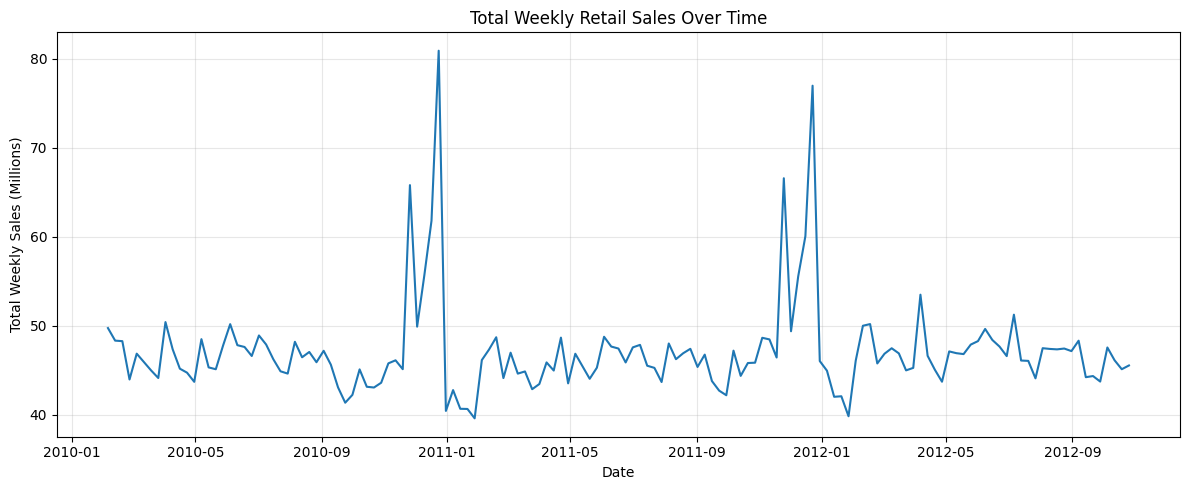

In [9]:
import matplotlib.pyplot as plt

# Plot total weekly sales over time
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_sales["Date"],
    weekly_sales["Weekly_Sales"] / 1_000_000
)

plt.title("Total Weekly Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales (Millions)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Findings

Throughout the majority of the observed timeframe, weekly retail sales demonstrated stability, consistently fluctuating between 43 million and 50 million. 

However the data highlights sharp seasonal peaks near the end of each year at about 81 million in late 2010 and 77 million in late 2011. Which then was followed by a decline in post-holiday sales, that was roughly at 40-46 million. 

 These repeating spikes confirm a strong seasonal influence on consumer buying behavior.

 Recommendation: Retail managers should use predictive historical modelling to ramp up inventory and staffing levels ahead of these predictable high-demand windows.



### 1.4 Sales Performance visualisations

#### Top 10 Stores By Sales Total

This bar chart shows a comparison between the ten stores that have the highest total recorded sales. 

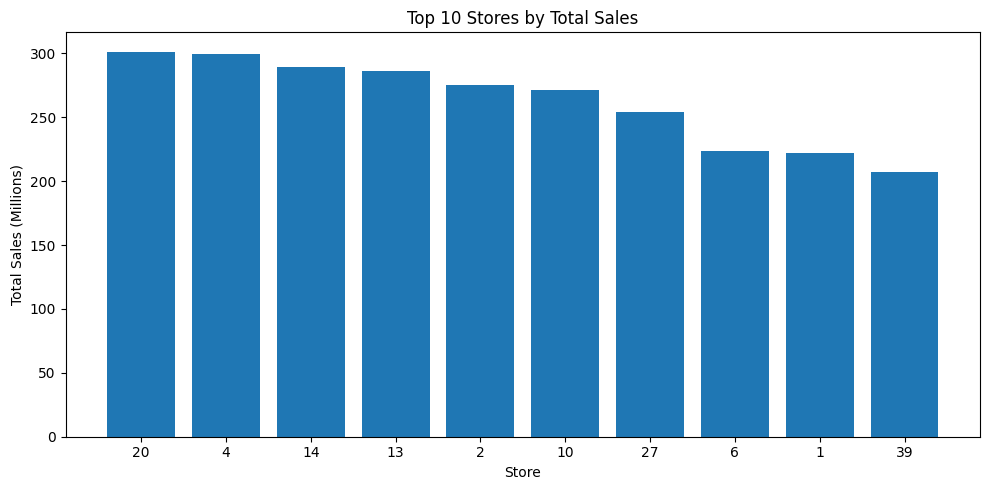

In [10]:
# Visualise the top 10 stores by total sales
top_10_stores = store_sales.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_10_stores["Store"].astype(str),
    top_10_stores["Weekly_Sales"] / 1_000_000
)

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales (Millions)")
plt.tight_layout()

plt.show()

#### Top 10 Departments By Sales Total

This bar chart shows a comparison between the ten departments that have the highest total recorded sales across all stores. 

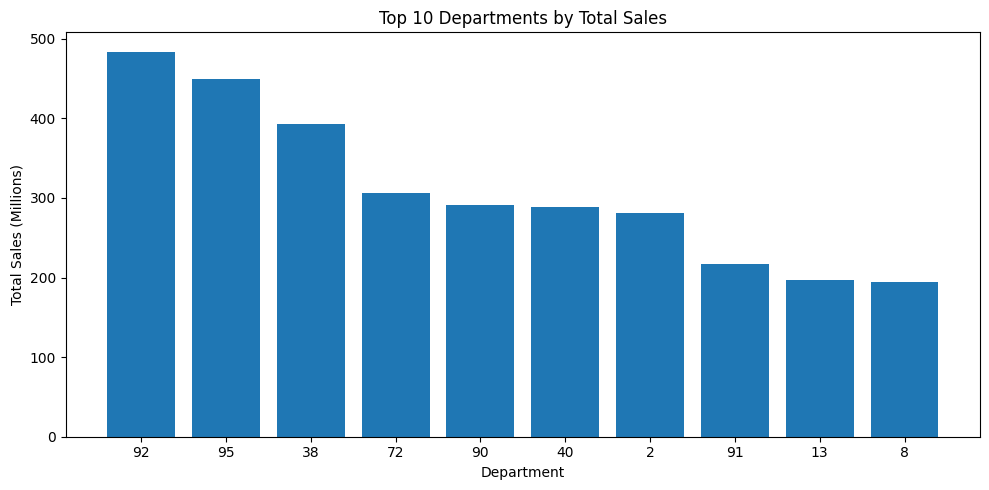

In [11]:
# Visualise the top 10 departments by total sales
top_10_departments = department_sales.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_10_departments["Dept"].astype(str),
    top_10_departments["Weekly_Sales"] / 1_000_000
)

plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Department")
plt.ylabel("Total Sales (Millions)")
plt.tight_layout()

plt.show()

### Business Requirement 1 - Conclusion

This analysis spotted the differences in sales performance across stores, departments and time.

**key Findings**
- Store 20 led total recorded sales at roughly 301.4 million, followed by Stores 4 and 14.

- Department 92 produced the highest total sales at roughly 483.9 million, followed by Departments 95 and 38.

- Overall weekly sales remained steady overall, though sharp seasonal spikes were appearing toward the end of 2010 and 2011. Which suggest recouring seasonal patterns.

**Business Recommendations**
- Leverage insights from top-performing stores and departments to guide inventory planning and resource allocation.

- Anticipate for periods of increased demand by examining historical sales trends.

-  Evaluate differences in store size and underlying regional factors before making direct performance comparisons.

**Limitations** 
Total sales figures to not reflect actual profitability, and identified seasonal spikes do not show the cause, just the patterns. 



## Business Requirement 2: Factors Affecting Sales

**Business Question:** How are holidays, markdown activity, store characteristics, and macroeconomic factors associated with weekly sales performance?

### 2.1 Holiday Vs Non-holiday sales

This section compares average sales patterns during holiday versus non-holiday weeks to assess whether seasonal events have an effect on overall performance.


In [12]:
# Do a comparison of average sales during holiday and non-holiday weeks
holiday_sales = (df.groupby("IsHoliday")["Weekly_Sales"]
.aggregate(["mean", "median", "count"])
.round(2)
.reset_index())

# Make the holiday labels easy to comprehend
holiday_sales["IsHoliday"] = holiday_sales["IsHoliday"].map({False: "Non-Holiday", True: "Holiday"})

holiday_sales

,IsHoliday,mean,median,count
0,Non-Holiday,15901.45,7589.95,391909
1,Holiday,17035.82,7947.74,29661


#### Findings

Average weekly sales per store-department record were higher during holiday weeks (17,035.82) than non-holiday weeks (15,901.45), which is about 7.1% higher.

The median was also slightly higher during holiday weeks (7,947.74 versus 7,589.95).

This suggests an association between holiday periods and higher sales, but it does not show that holiday caused the increase. As there were far fewer holidays recorded. 

This will be tested using a formal statistical hypothesis test in business requirement 3. 

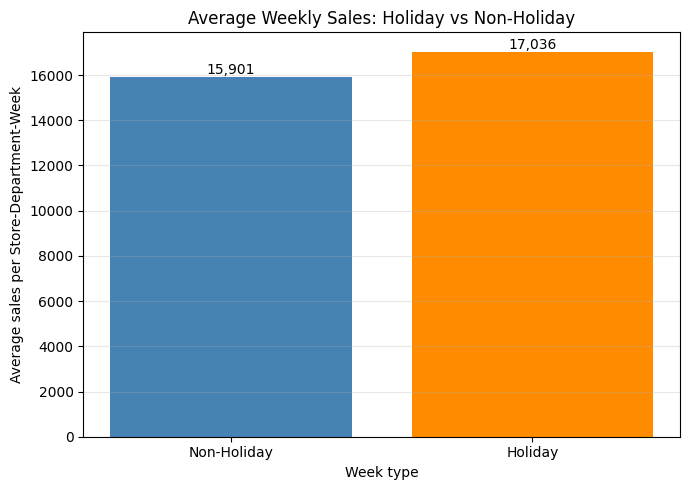

In [13]:
# Compare average weekly sales during holiday and non-holiday weeks

plt.figure(figsize=(7, 5))

bars = plt.bar(
    holiday_sales["IsHoliday"],
    holiday_sales["mean"],
    color=["steelblue", "darkorange"]
)

plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Week type")
plt.ylabel("Average sales per Store-Department-Week")
plt.grid(axis="y", alpha=0.3)

# Show the value above each bar
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 2.2 Markdown Activity and Sales

This analysis compares average sales between records that include markdown details and those where markdown data is absent

The aim is to examine potential links between markdown activity and sales whithout assuming that missin markdown values equal zero discounts.

In [15]:
# Compare sales by available markdown data
markdown_sales = (df.groupby("Markdown_Data_Available")["Weekly_Sales"]
.aggregate(["mean", "median", "count"])
.round(2)
.reset_index())

# Make the markdown labels easy to comprehend
markdown_sales["Markdown_Data_Available"] = (markdown_sales["Markdown_Data_Available"].map({False: "Markdown data missing", True: "Markdown data available"})
) 
markdown_sales

,Markdown_Data_Available,mean,median,count
0,Markdown data missing,15871.52,7654.84,270138
1,Markdown data available,16177.02,7537.87,151432


#### Findings 

Average weekly sales per store-department record were slightly higher when markdown data was available (16,177.02) than when it was missing (15,871.52). About 1.0% of difference.

However, the median was slightly lower when markdown data was available (7,537.87 versus 7,654.84).

Around 64% of records had missing markdown information, putting a constraint on the reliability of conclusions about promotional effectiveness.

**Business recommendation** 
Standardize the recording of promotional markdowns so management can reliably measure how discounts impact overall revenue.

### 2.3 Store Type and Size Versus Sales

This analysis looks whether there is a difference in sales performance depending the different store types (A, B, and C). This analysis also explores the relationship between store size and sales.

In [18]:
# Compare average sales across store types
store_type_sales = (df.groupby("Type")["Weekly_Sales"]
.aggregate(["mean", "median", "count"])
.round(2)
.reset_index())

store_type_sales

,Type,mean,median,count
0,A,20099.57,10105.17,215478
1,B,12237.08,6187.87,163495
2,C,9519.53,1149.67,42597


### Findings

Store Type A has the highest average sales per store-department-week record, at 20,099.57, followed by Type B at 12,237.08, and finally Type C at 9,519.53. This means that Type A's average is around 64% higher than Tyoe B and 111% higher than Type c.

Median sales follow the same rankings, although they are significantly lower than the means for the three store types. This signals that there are uneven sales spreads. 

The results gives the suggestion that store characteristics could have an association with sales performance, however there should be other investigations done before reaching a conclusion. Such as store sizes etc.

**Business Recommendations:** 
When comparing performance instead of just looking at total sales, retail managers should also consider store types and sizes.

#### Relationship Between Store Size And Sales

This section investigates whether store size correlates with total weekly sales. Sales numbers are grouped by store and data so they can be compared fairly.

In [20]:
# Calculate total weekly sales for each individual store
store_weekly_sales = (
    df.groupby(["Store", "Date", "Size"], as_index=False)["Weekly_Sales"]
    .sum()
)

# Calculate the average total weekly sales for each store
store_size_sales = (
    store_weekly_sales.groupby(["Store", "Size"], as_index=False)["Weekly_Sales"]
    .mean()
)

# Measure the correlation between store size and average weekly sales
size_correlation = store_size_sales["Size"].corr(store_size_sales["Weekly_Sales"])
print(f"Correlation between store size and average weekly sales: {size_correlation:.3f}")

store_size_sales.head()

Correlation between store size and average weekly sales: 0.846


,Store,Size,Weekly_Sales
0,1,151315,1.555264e+06
1,2,202307,1.925751e+06
2,3,37392,4.027044e+05
3,4,205863,2.094713e+06
4,5,34875,3.180118e+05


#### Findings

The Pearson correlation between store size and average total weekly sales was 0.846, showing a clear indication of a strong and positive linear relationship.

Thid demonstrates that larger stores usually generate higher total weekly sales. For instance store 4 which is a big store averaged 2.09 million in weekly sales, compared to the smaller store, store 5 generating 0.32 million i weekly sales.

However correlation doesnt equate to a direct cause, as there could be other factors explaining the reason bigger stores generate more in weekly sales than smaller shops do. These factors could be that the larger stores have more departments, greater customer capacity, as well as other characteristics influencing the sales.

**Business Recommendation:**
To ensure a fair comparison across different branches, retail managers should take store size into account instead of only relying on gross totals.

### 2.4 Temperature And Fuel Prices Versus Sales

This section looks at whether there is an affect from temperature and fuel prices on wekly retail sales.

Pearson correlation is used to measure the strength and direction of these relationships. Correlation does not equal to causation.

In [21]:
# Calculate total sales for each store type
# Keep one temperature value and one fuel price value for each store and week
weather_sales = (df.groupby(["Store", "Date"], as_index=False)
.aggregate({"Weekly_Sales": "sum", "Temperature": "first", "Fuel_Price": "first"}))

# Calculate the association with total weekly store sales
weather_correlation = (weather_sales[["Weekly_Sales", "Temperature", "Fuel_Price"]]
.corr()["Weekly_Sales"]
.drop("Weekly_Sales")
.round(3))

weather_correlation 

Temperature   -0.064
Fuel_Price     0.009
Name: Weekly_Sales, dtype: float64

#### Findings

Both temperature and fuel prices had a very weak correlation with total weekly sales, with temperature showing a slight negative association (-0.064), and fuel price showing almost no association (0.009).

These results show that neither temperature and fuel type have a strong linear relationship with sales across the observed store-week.

However, correlation does not establish causation, as other seasonal relationships might exist.



### CPI and Unemployment Versus Sales

This part investigates whether the consumer price index (CPI) and unemployment rates are associated with total weekly store sales.

In [22]:
# Calculate total sales and economic indicators for each store and week
economic_sales = (df.groupby(["Store", "Date"], as_index=False)
.aggregate({"Weekly_Sales": "sum", "CPI": "first", "Unemployment": "first"}))

# Do a calculation of Pearson correlation with weekly sales
economic_correlation = (economic_sales[["Weekly_Sales", "CPI", "Unemployment"]]
.corr()["Weekly_Sales"]
.drop("Weekly_Sales")
.round(3))

economic_correlation 

CPI            -0.073
Unemployment   -0.106
Name: Weekly_Sales, dtype: float64

#### Findings

Consumer price index (CPI) has a very weak negative association with total weekly sales (r-0.073).

Unemployment (r -0.106) also has a weak negative correlation with total weekly sales. 

This shows that although both these relationships are weak, higher CPI and Unemployment values were associated with lower sales rates.

This does not show either factors caused sales to change as other factors such as seasonal demands, store differences could have an effect.



## Business Requirement 2 - Conclussion

This analysis evaluated how seasonal holidays, promotional markdowns, store characteristics and economic conditions relate to overall retail sales.


**Key Findings:**
**Holiday impacts:** Average weekly sales per store-department went up by roughly 7.1% during the holiday period.
**Markdowns:** Available markdown records showed a slight boost of 1.9% in sales, however there was around 64% of missing markdown data, preventing a conclussion about the effectiveness of discounts.
**Store Type:** Type A stores recorded the highest mean sales volumes, followed by Type B and then Type C.
**Store Size:** Store size showed a possitive association with average total weekly store sales (r = 0.846).
**Temperature and Fuel Prices:** Both showed a near-zero linear relationship with sales. (Temperature = 0.064, Fuel Prices = 0.009).
**CPI and Unemployment:** Both the CPI (r = -0.073) and the Unemployment rate (r = 0.106) demonstrated weak negligible association with sales.

**Business Recommendations:**
1. Factor in season sales patterns when making a plan for inventory and staff.
2. Ensure store performance comparisons account for store size and store type.
3. Upgrade markdown data collection, to deliver more accurate peomotional analysis.
4. Examine additional metrics before drawing conclussions from low-strength correlations. 

**Limitations:** 
These conclussions do not identify the direct cause and effect on sales but rather correlational patterns. There is also un-recorded markdown information, differences between stores, and possible seasonal affects that are unknown, making it harder to come to a conclussion. 

